# Giao diện và biểu đồ báo cáo Nhóm 06

Notebook bổ sung cho `DoAn_Nhom06_DayDu.ipynb`. Phần này chứa toàn bộ source giao diện
Streamlit và toàn bộ code tạo ba biểu đồ bổ sung từ số liệu báo cáo.
Run All kiểm tra app thật bằng AppTest, mở server nội bộ để kiểm tra HTTP rồi dừng server,
đồng thời tạo lại ba biểu đồ trong thư mục output mới. Không huấn luyện lại ở notebook này.

In [1]:
import os, json, hashlib, socket, subprocess, sys, time, urllib.request
from pathlib import Path
from datetime import datetime, timezone, timedelta
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image as DisplayImage
ROOT=next((candidate for p in [Path.cwd(),*Path.cwd().parents]
           for candidate in [p,p/'unet-vs-unetplusplus-polyp']
           if (candidate/'configs/protocol_lock.json').is_file()),None)
if ROOT is None:raise FileNotFoundError('Mở notebook bên trong repo.')
os.chdir(ROOT)
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
RUNTIME=ROOT/'notebooks/.runtime/demo'
RUNTIME.mkdir(parents=True,exist_ok=True)
OUTPUT=ROOT/'results'/('notebook_tools_'+datetime.now(timezone(timedelta(hours=7))).strftime('%Y%m%d_%H%M%S_%f'))
OUTPUT.mkdir(parents=True,exist_ok=False)
print('Output:',OUTPUT.relative_to(ROOT))

Output: results\notebook_tools_20261115_050249_253000


## 1 Toàn bộ code giao diện Streamlit

Cell `%%writefile` ghi chính source đang nhìn thấy vào một file tạm để Streamlit chạy.
Streamlit cần script Python làm điểm vào; file tạm này được tạo tự động từ notebook,
không phải một phần code ẩn. Hai module nạp checkpoint và predict đã được trình bày
đầy đủ trong notebook chính. Giao diện kiểm tra SHA checkpoint A/B/C đã khóa trước khi nạp.

In [2]:
%%writefile notebooks/.runtime/demo/demo_notebook.py
"""Demo Streamlit cục bộ, dùng lại predict_image thay vì viết pipeline khác.

streamlit run members/tri/works_done/demo.py
"""

from pathlib import Path
import hashlib
import json
import sys

# Streamlit chạy file theo đường dẫn; đưa repo vào import path một lần.
PROJECT_ROOT = Path(__file__).resolve().parents[3]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0,str(PROJECT_ROOT))


def model_display_name(model_name, model_kwargs):
    """B và C có cùng tên class nhưng khác mục tiêu huấn luyện."""
    if model_name == "unet":
        return "U-Net"
    if model_name == "unetplusplus":
        return "U-Net++ có deep supervision" if model_kwargs.get("deep_supervision",False) else "U-Net++"
    raise ValueError("Mô hình không thuộc các thí nghiệm của đồ án")


def checkpoint_options(project_root=PROJECT_ROOT):
    """Ưu tiên đúng A/B/C đã khóa; fallback chỉ các run hoàn tất, bỏ pilot.

    Chỉ đọc JSON/checkpoint bytes để xác minh SHA, không đọc ảnh/mask test.
    """
    project_root = Path(project_root).resolve()
    lock_path = project_root / "configs" / "protocol_lock.json"
    options = []
    if lock_path.is_file():
        lock = json.loads(lock_path.read_text(encoding="utf-8"))
        if lock.get("schema_version") != 1 or lock.get("status") != "locked_before_test":
            raise ValueError("Danh sách mô hình chưa được khóa đúng giao thức")
        entries = sorted(lock.get("experiments",[]),key=lambda entry:str(entry.get("label","")))
        if not entries:
            raise ValueError("Kế hoạch đã khóa chưa có mô hình để trình diễn")
        for entry in entries:
            path = Path(str(entry["checkpoint_path"]).replace("\\","/"))
            path = path.resolve() if path.is_absolute() else (project_root / path).resolve()
            if not path.is_relative_to(project_root) or not path.is_file():
                raise ValueError("Không tìm thấy mô hình đã khóa trong thư mục đồ án")
            digest = hashlib.sha256()
            with path.open("rb") as stream:
                for chunk in iter(lambda:stream.read(1024 * 1024),b""):
                    digest.update(chunk)
            if digest.hexdigest() != entry.get("checkpoint_sha256"):
                raise ValueError("Mô hình hiện tại không khớp checkpoint đã khóa trong báo cáo")
            human_name = model_display_name(entry["model"],entry["config"].get("model_kwargs",{}))
            options.append({"checkpoint":str(path),"display_name":f"{entry['label']} — {human_name}"})
        return append_extended_runs(options, project_root)
    for path in sorted((project_root / "runs").glob("**/best.pt")):
        if any(part.startswith(("pilot_", "history_")) for part in path.relative_to(project_root / "runs").parts):
            continue
        summary_path = path.parent / "summary.json"
        if not summary_path.is_file():
            continue
        summary = json.loads(summary_path.read_text(encoding="utf-8"))
        if summary.get("status") not in {"completed","early_stopped"}:
            continue
        config = summary.get("config",{})
        human_name = model_display_name(summary.get("model_name",config.get("model")),config.get("model_kwargs",{}))
        prefix = path.parent.name.split("_",1)[0]
        display_name = f"{prefix} — {human_name}" if prefix in {"A","B","C"} else human_name
        options.append({"checkpoint":str(path.resolve()),"display_name":display_name})
    return options


def append_extended_runs(options, project_root):
    """Giữ A/B/C đã khóa; thêm run mở rộng hoàn tất dù tên là C_v2."""
    for path in sorted((project_root / "runs").glob("*/summary.json")):
        summary = json.loads(path.read_text(encoding="utf-8"))
        checkpoint = path.parent / "best.pt"
        if summary.get("trainer_kind") != "extension_20261111":
            continue
        if summary.get("status") not in {"completed", "early_stopped"} or not checkpoint.is_file():
            continue
        human = model_display_name(summary["model_name"], summary["config"]["model_kwargs"])
        options.append({"checkpoint": str(checkpoint.resolve()),
                        "display_name": f"Mở rộng {path.parent.name} — {human}"})
    return options


def main():
    # Optional dependency: đánh giá CLI không cần cài/chạy giao diện web.
    import streamlit as st
    from PIL import Image
    import torch
    from members.tri.works_done.checkpoint_io import load_checkpoint, resolve_device, resolve_project_path
    from members.tri.works_done.predict import predict_image, image_png_bytes

    st.set_page_config(page_title="Phân đoạn polyp — U-Net / U-Net++",layout="wide")
    st.title("Phân đoạn polyp với U-Net và U-Net++")
    st.write("Tải ảnh nội soi và xem vùng polyp mà mô hình dự đoán.")
    try:
        options = checkpoint_options()
    except (OSError,ValueError,KeyError) as error:
        st.error(f"Chưa thể đọc danh sách mô hình: {error}")
        return
    if not options:
        st.info("Chưa có mô hình huấn luyện hoàn tất. Mở lại demo sau khi có checkpoint để trình diễn.")
        return
    selected = st.sidebar.selectbox("Mô hình đã huấn luyện",options,format_func=lambda option:option["display_name"])
    device_label = st.sidebar.selectbox("Thiết bị",["Tự chọn","CPU"] + (["GPU"] if torch.cuda.is_available() else []))
    device_name = {"Tự chọn":"auto","CPU":"cpu","GPU":"cuda"}[device_label]
    st.sidebar.caption("Checkpoint được chọn bằng validation trước khi đánh giá test.")
    upload = st.file_uploader("Chọn ảnh nội soi",type=["jpg","jpeg","png"])
    if upload is None:
        return
    if not st.button("Phân đoạn ảnh",type="primary"):
        return
    try:
        torch.set_num_threads(4)
        device = resolve_device(device_name)
        with st.spinner("Đang dự đoán vùng polyp..."):
            model, checkpoint = load_checkpoint(resolve_project_path(selected["checkpoint"]),device)
            result = predict_image(model,checkpoint,Image.open(upload),device)
        human_name = model_display_name(checkpoint["model_name"],checkpoint["model_kwargs"])
        st.subheader(f"Kết quả: {human_name}")
        columns = st.columns(3)
        columns[0].image(result["image"],caption="Ảnh gốc",use_container_width=True)
        columns[1].image(result["mask_original"],caption="Mask dự đoán: trắng là polyp",use_container_width=True)
        columns[2].image(result["overlay"],caption="Vùng dự đoán tô xanh",use_container_width=True)
        st.caption(f"Ngưỡng xác suất: {result['threshold']:.2f}. Chưa có mask thật của ảnh tải lên nên chưa thể tính Dice/IoU.")
        st.download_button("Tải mask PNG",image_png_bytes(result["mask_original"]),"polyp_mask.png","image/png")
        st.download_button("Tải ảnh overlay",image_png_bytes(result["overlay"]),"polyp_overlay.png","image/png")
        st.info("Demo học thuật hỗ trợ trình bày đồ án; kết quả không phải chẩn đoán y khoa.")
    except (OSError,ValueError,RuntimeError,KeyError) as error:
        st.error(f"Chưa thể dự đoán: {error}")


if __name__ == "__main__":
    main()

Overwriting notebooks/.runtime/demo/demo_notebook.py


## 2 Chạy thật giao diện và kiểm tra widget

AppTest thực thi script Streamlit. Kiểm tra app không ném exception, có ba mô hình tham chiếu và đổi sang C được. Dự đoán ảnh thật, mask và overlay được chạy ở notebook chính.

In [3]:
from streamlit.testing.v1 import AppTest
app_path=RUNTIME/'demo_notebook.py'
app=AppTest.from_file(str(app_path)).run(timeout=90)
assert not app.exception,app.exception
assert app.title[0].value=='Phân đoạn polyp với U-Net và U-Net++'
options=app.sidebar.selectbox[0].options
assert all(any(s.startswith(k+' —') for s in options) for k in 'ABC')
# Widget giữ dict; AppTest cần giá trị gốc, không phải nhãn đã format.
locked=json.loads((ROOT/'configs/protocol_lock.json').read_text('utf-8'))
entry=next(e for e in locked['experiments'] if e['label']=='C')
c_option={'checkpoint':str((ROOT/entry['checkpoint_path']).resolve()),'display_name':options[2]}
app.sidebar.selectbox[0].set_value(c_option).run(timeout=90)
assert not app.exception,app.exception
print('AppTest passed; các lựa chọn mô hình:',options)

2026-11-15 05:02:49.687 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


AppTest passed; các lựa chọn mô hình: ['A — U-Net', 'B — U-Net++', 'C — U-Net++ có deep supervision', 'Mở rộng submission_smoke_B_20261111 — U-Net++', 'Mở rộng submission_smoke_C_20261111 — U-Net++ có deep supervision', 'Mở rộng submission_smoke_continuous_20261111 — U-Net', 'Mở rộng submission_smoke_resume_20261111 — U-Net']


## 3 Mở và kiểm tra server nội bộ

Hai cell sau khởi động rồi dừng server để Run All kết thúc sạch. Khi trình diễn lâu hơn, dùng lệnh mở app ở README hoặc chỉ chạy cell mở server và giữ cell dừng lại cho đến khi xem xong.

In [4]:
with socket.socket() as port_socket:
    port_socket.bind(('127.0.0.1',0))
    port=port_socket.getsockname()[1]
log_file=(OUTPUT/'streamlit.log').open('w',encoding='utf-8')
server=subprocess.Popen([sys.executable,'-X','utf8','-B','-m','streamlit','run',str(app_path),
            '--server.address','127.0.0.1','--server.port',str(port),'--server.headless','true',
            '--browser.gatherUsageStats','false'],cwd=ROOT,stdout=log_file,stderr=subprocess.STDOUT)
url=f'http://127.0.0.1:{port}'
try:
    for _ in range(90):
        if server.poll() is not None:raise RuntimeError('Streamlit dừng sớm; đọc streamlit.log.')
        try:
            with urllib.request.urlopen(url+'/_stcore/health',timeout=2) as response:
                healthy=response.status==200 and response.read().decode().strip()=='ok'
            if healthy:break
        except OSError:pass
        time.sleep(.5)
    else:raise TimeoutError('Streamlit chưa sẵn sàng sau 45 giây.')
    display(Markdown('[Mở giao diện đang chạy]('+url+')'))
    print('HTTP health: 200 OK')
except BaseException:
    server.terminate();server.wait(timeout=15);log_file.close()
    raise

[Mở giao diện đang chạy](http://127.0.0.1:50601)

HTTP health: 200 OK


In [5]:
server.terminate()
try:server.wait(timeout=15)
except subprocess.TimeoutExpired:server.kill();server.wait(timeout=5)
log_file.close()
assert server.poll() is not None
print('Đã dừng server do notebook tạo. Khi demo, chạy lại cell mở server và dừng sau khi xem.')

Đã dừng server do notebook tạo. Khi demo, chạy lại cell mở server và dừng sau khi xem.


## 4 Toàn bộ code ba biểu đồ bổ sung

Nguồn là CSV chính thức đã công bố. Output ở thư mục mới của notebook này.
Hình thứ nhất so số tham số; hình thứ hai ΔDice và bootstrap cùng số ảnh thắng/thua;
hình thứ ba so bốn head và mean xác suất. Không đưa số liệu từ bài báo vào cột kết quả nhóm.

In [6]:
OUT=OUTPUT/'reference_charts'
COLORS=['#386CB0','#D97836','#32905D']

In [7]:
def sha(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

In [8]:
def finish(fig, name):
    fig.savefig(OUT/name, dpi=220, bbox_inches='tight', facecolor='white')
    plt.close(fig)

In [9]:
def build_reference_charts():
    OUT.mkdir(parents=True, exist_ok=True)
    plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':12,
                         'axes.spines.top':False, 'axes.spines.right':False})
    comparison_path=ROOT/'results/comparison/comparison.csv'
    stats_path=ROOT/'results/report_figures/checklist_20261114/paired_statistics.csv'
    head_paths={s:ROOT/f'results/report_figures/checklist_20261114/head_metrics_{s}.csv' for s in ['val','test']}
    comparisons=pd.read_csv(comparison_path).set_index('experiment')
    stats=pd.read_csv(stats_path).set_index('comparison').loc[['B_vs_A','C_vs_B','C_vs_A']]
    for p in [ROOT/f'results/{s}_test/per_image.csv' for s in 'ABC']:
        data=pd.read_csv(p);assert len(data)==150 and data.image_id.is_unique
    assert all((stats.images_up+stats.images_down+stats.images_equal)==150)

    fig,ax=plt.subplots(figsize=(9.4,4.2),layout='constrained')
    values=comparisons.loc[list('ABC'),'parameters'].to_numpy()
    labels=['A · U-Net','B · U-Net++','C · U-Net++ + DS']
    ax.barh(np.arange(3),values/1e6,color=COLORS,height=.54)
    ax.set_yticks(range(3),labels);ax.invert_yaxis();ax.set_xlim(0,11.5)
    for i,(v,blocks,heads) in enumerate(zip(values,[9,15,15],[1,1,4])):
        ax.text(v/1e6+.12,i,f'{v:,}'.replace(',','.')+f'\n{blocks} DoubleConv · {heads} head',va='center',fontsize=11)
    ax.set_xlabel('Số tham số (triệu)');ax.set_title('Dung lượng mô hình theo cấu hình đã huấn luyện',pad=14)
    ax.text(.02,-.28,'B nhiều hơn A 16,5%; C chỉ thêm 99 tham số so với B.\nĐây là số tham số, không phải tốc độ hay chất lượng.',transform=ax.transAxes,fontsize=10)
    finish(fig,'model_parameters.png')

    fig,(left,right)=plt.subplots(2,1,figsize=(8.5,7.4),layout='constrained')
    y=np.arange(3);names=['B so với A','C so với B','C so với A']
    delta=stats.delta.to_numpy();lo=stats.ci_low.to_numpy();hi=stats.ci_high.to_numpy()
    left.errorbar(delta,y,xerr=[delta-lo,hi-delta],fmt='o',color='#315C90',capsize=6,markersize=7)
    left.axvline(0,color='#777',linestyle='--',linewidth=1)
    left.set_yticks(y,names);left.invert_yaxis();left.set_xlim(-.01,.24)
    left.set_xlabel('Chênh lệch Dice');left.set_title('Chênh lệch trung bình và KTC 95%')
    for i,row in enumerate(stats.itertuples()):
        label=f'+{row.delta:.4f}\np={row.p_wilcoxon:.2g}'
        left.text(row.ci_high+.006,i,label,va='center',fontsize=11)
    offset=np.zeros(3)
    for column,color,label in [('images_up','#32905D','Tốt hơn'),('images_equal','#B6BBC2','Bằng nhau'),('images_down','#CD655B','Kém hơn')]:
        vals=stats[column].to_numpy();right.barh(y,vals,left=offset,color=color,label=label,height=.55)
        for i,(v,start) in enumerate(zip(vals,offset)):
            if v>=10:right.text(start+v/2,i,str(v),ha='center',va='center',color='white',fontweight='bold')
        offset+=vals
    right.set_yticks(y,names);right.invert_yaxis();right.set_xlim(0,150)
    right.set_xlabel('Số ảnh test');right.set_title('So sánh từng cặp trên cùng 150 ảnh')
    right.legend(loc='upper center',bbox_to_anchor=(.5,-.14),ncol=3,fontsize=9)
    fig.suptitle('Checkpoint cố định · bootstrap 10.000 lần · Wilcoxon hai phía',fontsize=12)
    finish(fig,'paired_dice_uncertainty.png')

    heads={s:pd.read_csv(p,dtype={'head':str}).set_index('head').loc[['1','2','3','4','mean']] for s,p in head_paths.items()}
    fig,ax=plt.subplots(figsize=(9.4,4.4),layout='constrained');x=np.arange(5);w=.34
    for split,color,shift,name in [('val','#386CB0',-w/2,'Validation'),('test','#32905D',w/2,'Test')]:
        bars=ax.bar(x+shift,heads[split].dice,width=w,color=color,label=name)
        ax.bar_label(bars,fmt='%.3f',padding=3,fontsize=11)
    ax.set_xticks(x,['Head 1','Head 2','Head 3','Head 4\n(chính)','Mean xác suất\n4 head'])
    ax.set_ylim(0,1);ax.set_ylabel('Dice trung bình theo ảnh');ax.legend(loc='upper left')
    ax.set_title('Phân tích bổ sung checkpoint C · bảng chính vẫn dùng head 4',pad=12)
    finish(fig,'deep_supervision_heads.png')

    files=[comparison_path,stats_path,*head_paths.values()]
    manifest={'sources':{p.relative_to(ROOT).as_posix():sha(p) for p in files},
              'figures':['model_parameters.png','paired_dice_uncertainty.png','deep_supervision_heads.png'],
              'scope':'Charts of fixed recorded results; no new training, model selection or clinical claims.'}
    (OUT/'chart_sources.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
    print(json.dumps(manifest,indent=2))

{
  "sources": {
    "results/comparison/comparison.csv": "377f590ac9648a37591dddfe77cf9590ca8d07c23f8ffd3601eb0a031912831d",
    "results/report_figures/checklist_20261114/paired_statistics.csv": "467a1805d0392c2b9a2ce679a160e965c97eb17beb7032628858cbfe00d9a4bc",
    "results/report_figures/checklist_20261114/head_metrics_val.csv": "010a4595496abacced969b2839a67543aca93f06a62b091b13c56d32d8900131",
    "results/report_figures/checklist_20261114/head_metrics_test.csv": "0597c28636b99a984af90518ca5745594ccff621add7e222a08e493834ba4725"
  },
  "figures": [
    "model_parameters.png",
    "paired_dice_uncertainty.png",
    "deep_supervision_heads.png"
  ],
  "scope": "Charts of fixed recorded results; no new training, model selection or clinical claims."
}


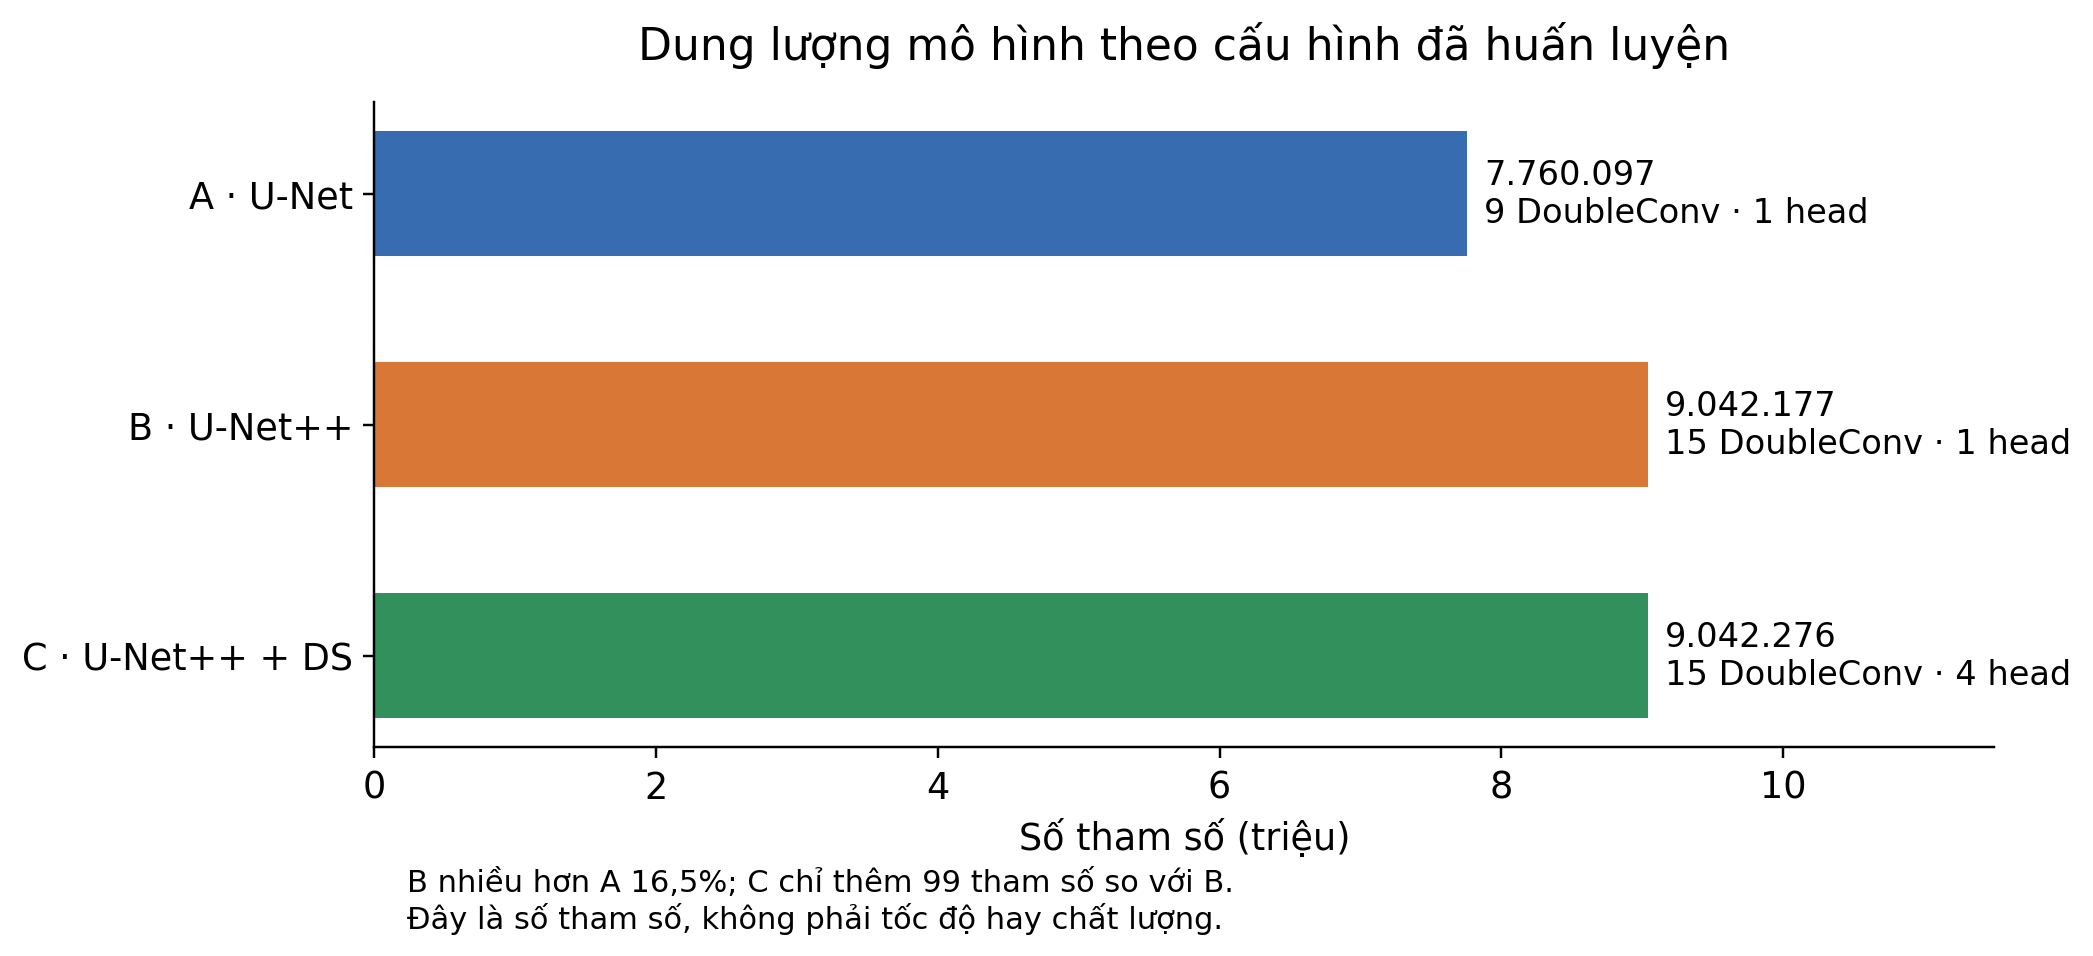

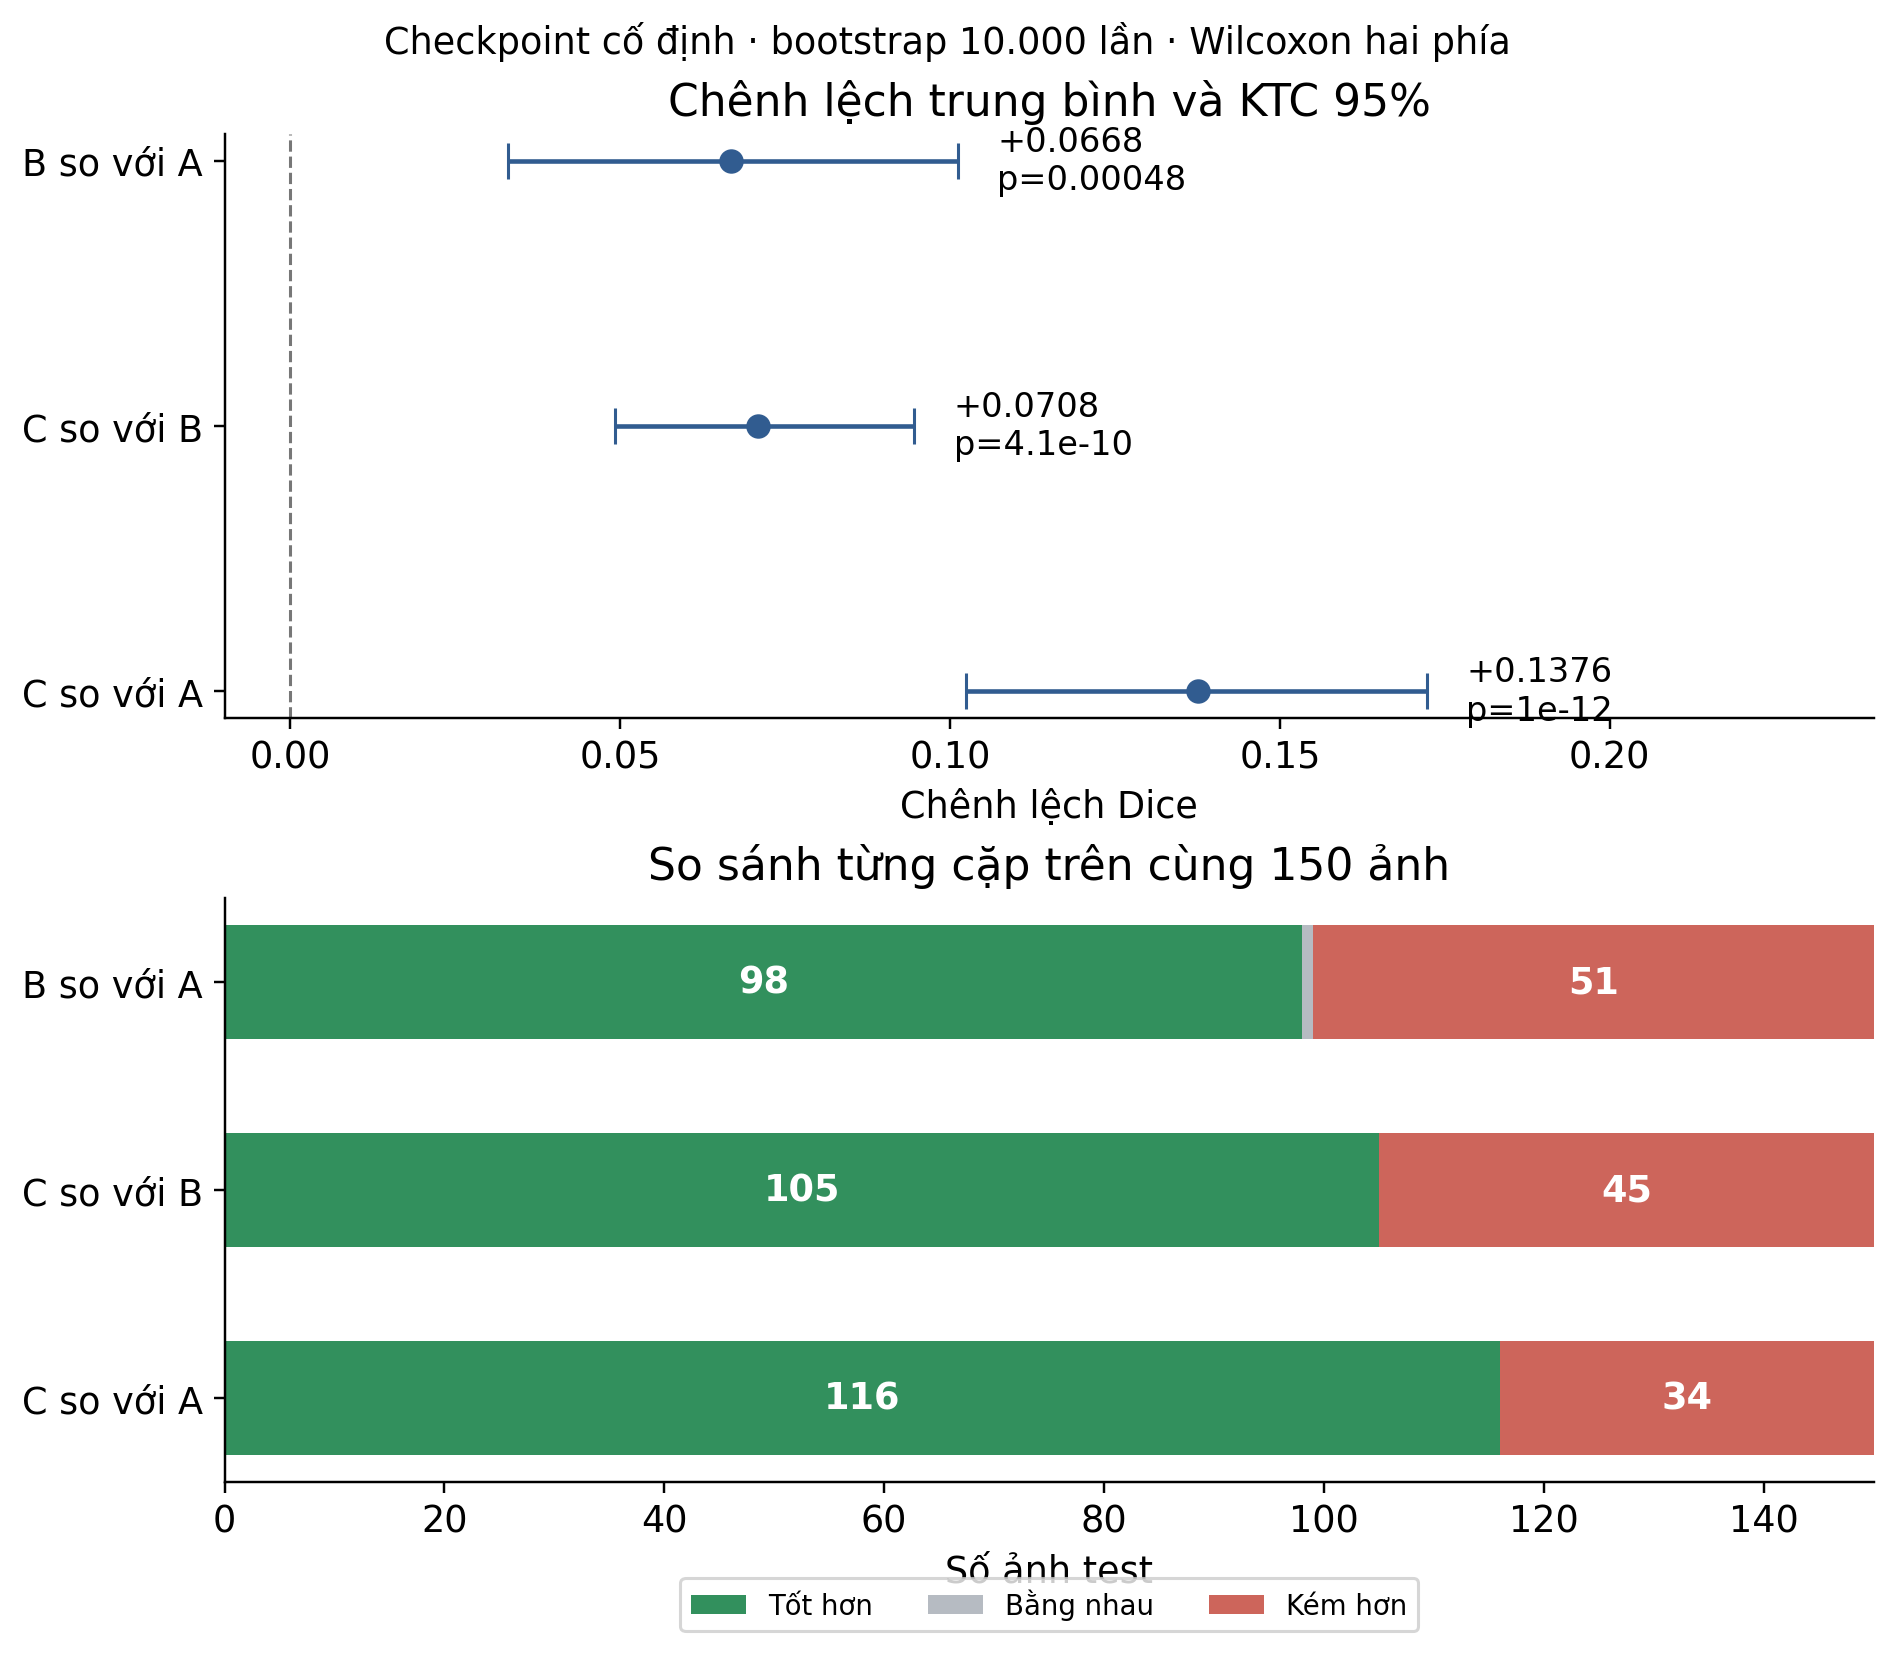

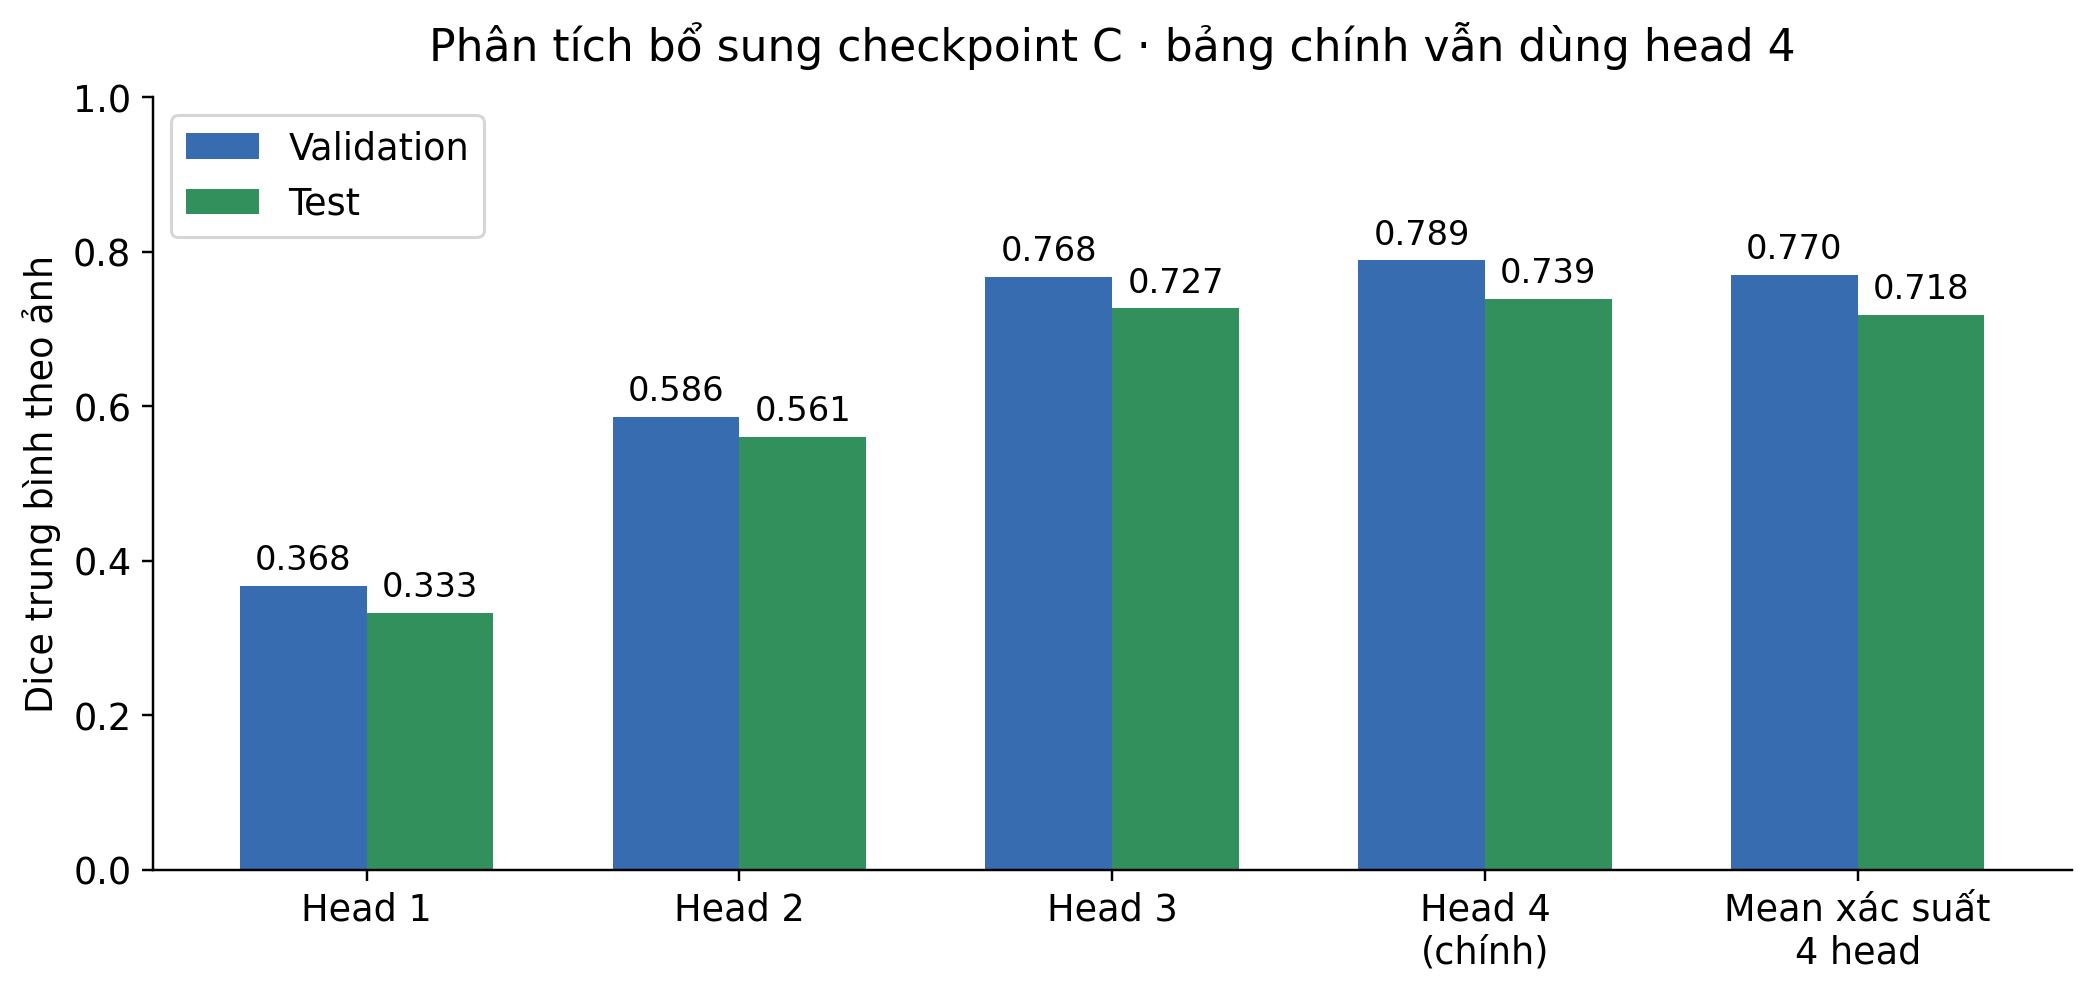

Ba biểu đồ được tạo lại từ đúng CSV, nguồn và SHA ghi trong chart_sources.json.


In [10]:
build_reference_charts()
for name in ['model_parameters.png','paired_dice_uncertainty.png','deep_supervision_heads.png']:
    assert (OUT/name).is_file()
    display(DisplayImage(filename=str(OUT/name),width=900))
print('Ba biểu đồ được tạo lại từ đúng CSV, nguồn và SHA ghi trong chart_sources.json.')

## 5 Minh chứng

Chạy app không yêu cầu đưa token hay dữ liệu riêng lên dịch vụ bên ngoài.
Các hình kiến trúc do Duy cung cấp đã được chèn trong notebook chính và báo cáo Word;
nguồn hình paper và số liệu được ghi riêng trong các tệp JSON.

In [11]:
receipt={'status':'passed','streamlit_apptest':'passed','http_health':'200 OK','server_stopped':server.poll() is not None,
         'reference_charts':3,'output':str(OUTPUT.relative_to(ROOT)),
         'app_source_matches_module':app_path.read_text('utf-8')==(ROOT/'members/tri/works_done/demo.py').read_text('utf-8')}
assert receipt['app_source_matches_module']
(OUTPUT/'execution_receipt.json').write_text(json.dumps(receipt,indent=2),encoding='utf-8')
print(json.dumps(receipt,indent=2))

{
  "status": "passed",
  "streamlit_apptest": "passed",
  "http_health": "200 OK",
  "server_stopped": true,
  "reference_charts": 3,
  "output": "results\\notebook_tools_20261115_050249_253000",
  "app_source_matches_module": true
}
